# 🤖 Лаборатория обучения RL-агента исполнения (Maskable PPO + L2 FIFO)
Этот блокнот позволяет в реальном времени запускать, отслеживать и препарировать обучение **RL-агента микроструктурного исполнения (`MaskableActorCritic`)** поверх 10-уровневого L2 FIFO-стакана SafeTrade и сигналов триады ансамблей (`H=5s, 12s, 25s`).

⚡ Загрузка готового кэша RL-полигона (Триада H=5,12,25s): rl_triad_lob_cache_prl_72h.npz
✅ Размерность матрицы состояния рынка: (259200, 28) | Период: 2026-10-20 08:16:05+03:00 ➔ 2026-10-23 08:16:04+03:00


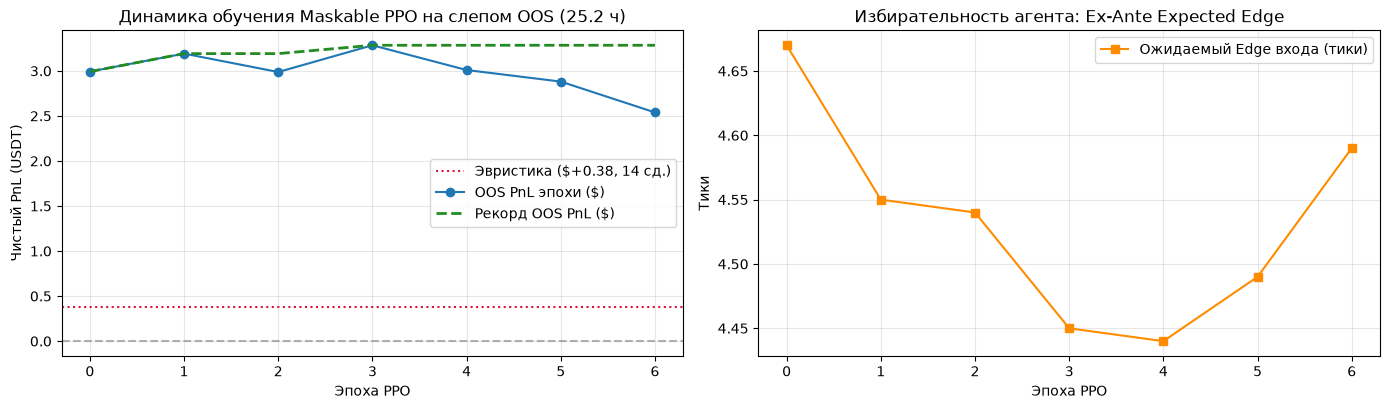

,epoch,pnl_usd,pnl_pct,trades,hours,exp_edge_ticks,critic_v_ticks,real_pnl_per_trade_usd,best_pnl_usd
0,0,2.9922,19.95,148,25.2,4.67,-0.07,0.0202,2.9922
1,1,3.1916,21.28,156,25.2,4.55,-0.11,0.0205,3.1916
2,2,2.9873,19.92,153,25.2,4.54,-0.29,0.0195,3.1916
3,3,3.2842,21.89,155,25.2,4.45,-0.52,0.0212,3.2842
4,4,3.0095,20.06,136,25.2,4.44,-0.51,0.0221,3.2842
5,5,2.8810,19.21,127,25.2,4.49,-0.58,0.0227,3.2842
6,6,2.5388,16.93,117,25.2,4.59,-0.57,0.0217,3.2842


In [2]:
# 📊 ЯЧЕЙКА 1: Обзор кэша полигона и кривой сходимости последнего обучения
import importlib
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import _tools.train_rl_execution as _rl_mod
importlib.reload(_rl_mod)
from _tools.train_rl_execution import build_or_load_rl_cache

TAIL_HOURS = 72.0
data = build_or_load_rl_cache(coin="prl", tail_hours=TAIL_HOURS)
print(f"✅ Размерность матрицы состояния рынка: {data['X_market'].shape} | Период: {data['ts'][0]} ➔ {data['ts'][-1]}")

hist_path = Path("models/prl/rl_execution/training_history.json")
if hist_path.exists():
    h_data = json.loads(hist_path.read_text())
    df_h = pd.DataFrame(h_data["history"])
    base = h_data["baseline"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
    ax1.axhline(0.0, color="gray", ls="--", alpha=0.6)
    ax1.axhline(base["pnl_usd"], color="crimson", ls=":", label=f"Эвристика (${base['pnl_usd']:+.2f}, {base['trades']} сд.)")
    ax1.plot(df_h["epoch"], df_h["pnl_usd"], marker="o", label="OOS PnL эпохи ($)")
    ax1.plot(df_h["epoch"], df_h["best_pnl_usd"], ls="--", color="forestgreen", lw=2, label="Рекорд OOS PnL ($)")
    ax1.set_title("Динамика обучения Maskable PPO на слепом OOS (25.2 ч)")
    ax1.set_xlabel("Эпоха PPO"); ax1.set_ylabel("Чистый PnL (USDT)"); ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(df_h["epoch"], df_h["exp_edge_ticks"], marker="s", color="darkorange", label="Ожидаемый Edge входа (тики)")
    ax2.set_title("Избирательность агента: Ex-Ante Expected Edge")
    ax2.set_xlabel("Эпоха PPO"); ax2.set_ylabel("Тики"); ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    display(df_h)

In [ ]:
# 🚀 ЯЧЕЙКА 2: Запуск живого обучения RL-агента с онлайн-графиком после каждой эпохи
import importlib
import _tools.train_rl_execution as _rl_mod
importlib.reload(_rl_mod)

res = _rl_mod.train_rl_agent(
    coin="prl",
    tail_hours=72.0,
    ppo_epochs=25,
    steps_per_epoch=16384,
    live_plot=True,
)

⚡ Загрузка готового кэша RL-полигона (Триада H=5,12,25s): rl_triad_lob_cache_prl_72h.npz


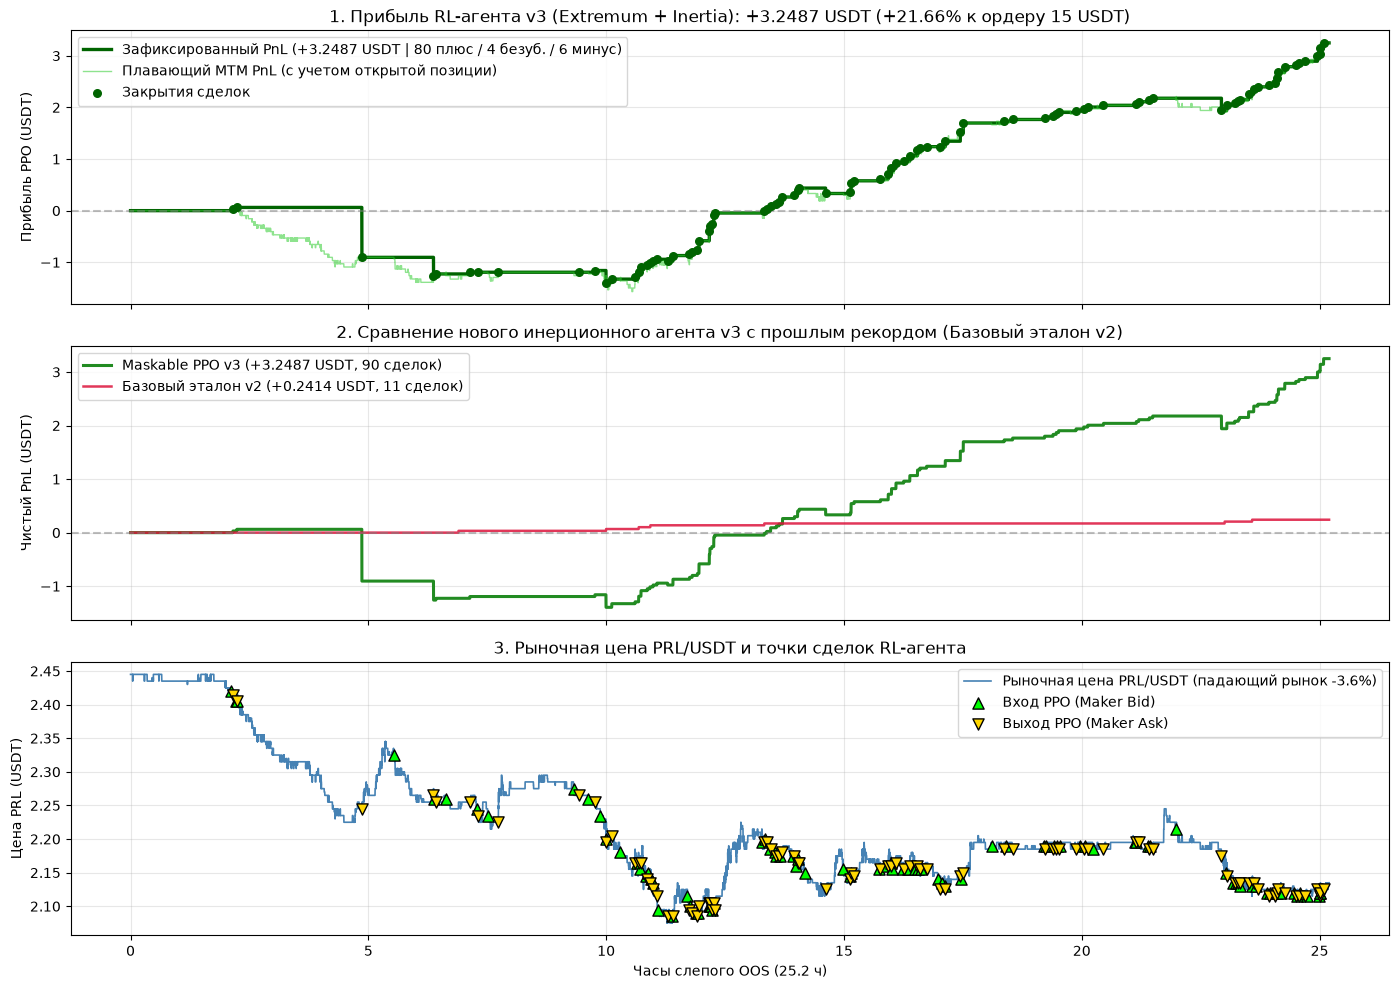


🏆 Сделки лучшей политики Maskable PPO (90 шт.):


,entry_ts,exit_ts,hold_sec,entry_price,exit_action,net_pnl_usd,cum_pnl_usd
0,2026-10-22 09:11:23+03:00,2026-10-22 09:13:08+03:00,105,2.415,Maker Ask (Passive),0.0311,0.0311
1,2026-10-22 09:16:34+03:00,2026-10-22 09:18:04+03:00,90,2.405,Maker Ask (Passive),0.0312,0.0622
2,2026-10-22 09:18:13+03:00,2026-10-22 11:55:50+03:00,9457,2.405,Maker Ask (Passive),-0.9667,-0.9045
3,2026-10-22 12:36:18+03:00,2026-10-22 13:26:14+03:00,2996,2.325,Maker Ask (Passive),-0.3548,-1.2593
4,2026-10-22 13:27:17+03:00,2026-10-22 13:29:14+03:00,117,2.255,Maker Ask (Passive),0.0333,-1.2261
...,...,...,...,...,...,...,...
85,2026-10-23 07:39:00+03:00,2026-10-23 07:45:59+03:00,419,2.115,Maker Ask (Passive),0.0355,2.8941
86,2026-10-23 07:48:49+03:00,2026-10-23 08:01:21+03:00,752,2.115,Maker Ask (Passive),0.1064,3.0005
87,2026-10-23 08:03:18+03:00,2026-10-23 08:04:33+03:00,75,2.115,Maker Ask (Passive),0.0355,3.0360
88,2026-10-23 08:04:49+03:00,2026-10-23 08:04:50+03:00,1,2.115,Maker Ask (Passive),0.1064,3.1424



📉 Сделки базовой эвристики (11 шт.):


,entry_ts,exit_ts,hold_sec,entry_price,exit_action,net_pnl_usd,cum_pnl_usd
0,2026-10-22 09:41:56+03:00,2026-10-22 09:43:58+03:00,122,2.350,Maker Ask (Passive),0.0000,0.0000
1,2026-10-22 13:47:40+03:00,2026-10-22 13:57:42+03:00,602,2.240,Maker Ask (Passive),0.0335,0.0335
2,2026-10-22 17:03:46+03:00,2026-10-22 17:03:53+03:00,7,2.215,Maker Ask (Passive),0.0339,0.0673
3,2026-10-22 17:04:03+03:00,2026-10-22 17:09:12+03:00,309,2.200,Maker Ask (Passive),0.0000,0.0673
4,2026-10-22 17:42:24+03:00,2026-10-22 17:45:02+03:00,158,2.160,Maker Ask (Passive),0.0347,0.1021
5,2026-10-22 17:58:27+03:00,2026-10-22 17:59:43+03:00,76,2.140,Maker Ask (Passive),0.0350,0.1371
6,2026-10-22 18:08:21+03:00,2026-10-22 18:30:50+03:00,1349,2.105,Maker Ask (Passive),0.0000,0.1371
7,2026-10-22 19:59:40+03:00,2026-10-22 20:02:38+03:00,178,2.195,Maker Ask (Passive),0.0000,0.1371
8,2026-10-22 20:23:00+03:00,2026-10-22 20:23:28+03:00,28,2.195,Maker Ask (Passive),0.0342,0.1713
9,2026-10-23 06:04:06+03:00,2026-10-23 06:04:13+03:00,7,2.155,Maker Ask (Passive),0.0348,0.2061


In [4]:
# 🔍 ЯЧЕЙКА 3: Детальный слепой OOS-экзамен лучшего чекпоинта (3 панели: Крупный план PPO, Сравнение с эвристикой, Входы на цене)
import importlib
import _tools.train_rl_execution as _rl_mod
importlib.reload(_rl_mod)

df_ppo_trades, df_base_trades = _rl_mod.inspect_and_plot_rl_oos(coin="prl", tail_hours=72.0)
print(f"\n🏆 Сделки лучшей политики Maskable PPO ({len(df_ppo_trades)} шт.):")
display(df_ppo_trades)
print(f"\n📉 Сделки базовой эвристики ({len(df_base_trades)} шт.):")
display(df_base_trades.head(10))